# 06 · Evaluation & Selection — *from scratch*

**Phase goal:** take the CV winner, refit it, judge it on the **held-out test
set** (data it has never seen), and check it against the **business KPIs**.

CV tells us which model to pick; the **held-out test set** gives an honest
estimate of how it will do on genuinely new cars.

In [1]:
# --- Self-contained setup: schema, cleaning, features, bands ---------------
# (In the real project these live in src/car_pricing/*. Here we write them out
#  so this notebook imports nothing from the project.)
import warnings
warnings.filterwarnings("ignore")   # hide library deprecation notices for clean output

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder

DATA_PATH     = "../data/raw/cars24-car-price-cleaned-new.csv.gz"
TARGET        = "selling_price"
TARGET_ENCODE = ["make", "model"]
NUMERIC       = ["km_driven", "mileage", "engine", "max_power", "age"]
FLAGS         = ["Individual", "Trustmark Dealer", "Diesel", "Electric", "LPG",
                 "Petrol", "Manual", "Seats_5", "Seats_Above_5"]
FEATURES      = TARGET_ENCODE + NUMERIC + FLAGS
BAND_LABELS   = ["Low", "Medium", "High"]
TEST_SIZE, RANDOM_STATE, CV_FOLDS = 0.2, 42, 3


def clean(df):
    df = df.rename(columns={"5": "Seats_5", ">5": "Seats_Above_5"})
    df = df.dropna(subset=[TARGET])
    df = df[df[TARGET] > 0].dropna()
    for c in TARGET_ENCODE:
        df[c] = df[c].astype(str).str.strip().str.upper()
    return df.reset_index(drop=True)


def build_preprocessor():
    """Target-encode make/model; pass numeric + flag columns through."""
    return ColumnTransformer([
        ("target_enc", TargetEncoder(target_type="continuous", random_state=RANDOM_STATE), TARGET_ENCODE),
        ("passthrough", "passthrough", NUMERIC + FLAGS),
    ], remainder="drop")


def band_edges(prices):
    edges = [float(np.quantile(prices, q)) for q in (0.0, 1/3, 2/3, 1.0)]
    for i in range(1, len(edges)):
        if edges[i] <= edges[i - 1]:
            edges[i] = edges[i - 1] + 0.01
    return [round(e, 2) for e in edges]


def price_to_band(prices, edges):
    prices = np.asarray(prices, dtype=float)
    idx = np.clip(np.digitize(prices, edges[1:-1]), 0, len(BAND_LABELS) - 1)
    return np.array(BAND_LABELS)[idx]


df = clean(pd.read_csv(DATA_PATH))
X = df[FEATURES].copy()
y = df[TARGET].copy()
print(f"{len(df):,} rows | {len(FEATURES)} features")

19,820 rows | 16 features


In [2]:
def model_zoo():
    """Name -> a fresh, unfitted regressor. Modest, comparable settings so the
    bake-off is a FAIR fight, not a tuning contest (we tune later, in nb 08)."""
    from sklearn.linear_model import Ridge
    from sklearn.tree import DecisionTreeRegressor
    from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

    zoo = {
        "Ridge (linear)": Ridge(alpha=1.0, random_state=RANDOM_STATE),
        "Decision Tree":  DecisionTreeRegressor(max_depth=12, min_samples_leaf=8, random_state=RANDOM_STATE),
        "Random Forest":  RandomForestRegressor(n_estimators=200, max_depth=18,
                                                min_samples_leaf=4, n_jobs=-1, random_state=RANDOM_STATE),
        "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=400, learning_rate=0.06,
                                                              max_depth=8, random_state=RANDOM_STATE),
    }
    # Add the gradient-boosting libraries only if they are installed.
    try:
        from xgboost import XGBRegressor
        zoo["XGBoost"] = XGBRegressor(n_estimators=500, max_depth=6, learning_rate=0.05,
                                      subsample=0.9, colsample_bytree=0.9, n_jobs=-1,
                                      random_state=RANDOM_STATE, verbosity=0)
    except ImportError:
        pass
    try:
        from lightgbm import LGBMRegressor
        zoo["LightGBM"] = LGBMRegressor(n_estimators=600, num_leaves=63, learning_rate=0.05,
                                        subsample=0.9, colsample_bytree=0.9, n_jobs=-1,
                                        random_state=RANDOM_STATE, verbosity=-1)
    except ImportError:
        pass
    return zoo


print("candidates:", list(model_zoo()))

candidates: ['Ridge (linear)', 'Decision Tree', 'Random Forest', 'HistGradientBoosting', 'XGBoost', 'LightGBM']


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Same split as nb 05 (same random_state => identical rows).
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)

# We pick LightGBM as the winner here (a top scorer that also SERVES cleanly as a
# single portable pipeline — see nb 08 for the full XGBoost-vs-LightGBM story).
winner_name = "LightGBM" if "LightGBM" in model_zoo() else "HistGradientBoosting"

# Bundle preprocessing + model into ONE object so the encoder travels with it.
pipe = Pipeline([
    ("preprocess", build_preprocessor()),
    ("model", model_zoo()[winner_name]),
])
pipe.fit(X_tr, y_tr)
pred = pipe.predict(X_te)
print("shipped model:", winner_name)

shipped model: LightGBM


In [4]:
# --- Score it on the held-out test set against the business KPIs ---
edges = band_edges(y_tr)                      # bands defined from TRAIN prices only
true_band = price_to_band(y_te, edges)
pred_band = price_to_band(pred, edges)

metrics = {
    "R2":            round(float(r2_score(y_te, pred)), 4),
    "MAE_lakhs":     round(float(mean_absolute_error(y_te, pred)), 3),
    "RMSE_lakhs":    round(float(np.sqrt(mean_squared_error(y_te, pred))), 3),
    "band_accuracy": round(float((true_band == pred_band).mean()), 4),
}

KPI = {"max_mae_lakhs": 1.0, "min_r2": 0.85, "min_band_accuracy": 0.70}
gate = {
    "mae_ok":  metrics["MAE_lakhs"] <= KPI["max_mae_lakhs"],
    "r2_ok":   metrics["R2"] >= KPI["min_r2"],
    "band_ok": metrics["band_accuracy"] >= KPI["min_band_accuracy"],
}
gate["ALL_PASS"] = all(gate.values())

for k, v in metrics.items():
    print(f"  {k:14s}: {v}")
print(f"\n  KPI gate      : {'PASS' if gate['ALL_PASS'] else 'FAIL'}  {gate}")

  R2            : 0.9568
  MAE_lakhs     : 0.664
  RMSE_lakhs    : 1.022
  band_accuracy : 0.8582

  KPI gate      : PASS  {'mae_ok': True, 'r2_ok': True, 'band_ok': True, 'ALL_PASS': True}


### Look at the errors, don't just trust one number
Two quick diagnostics:
- **Predicted vs actual** — points should hug the red diagonal.
- **Residuals** (`predicted − actual`) — should be a tight cloud centred on zero,
  with no obvious pattern.

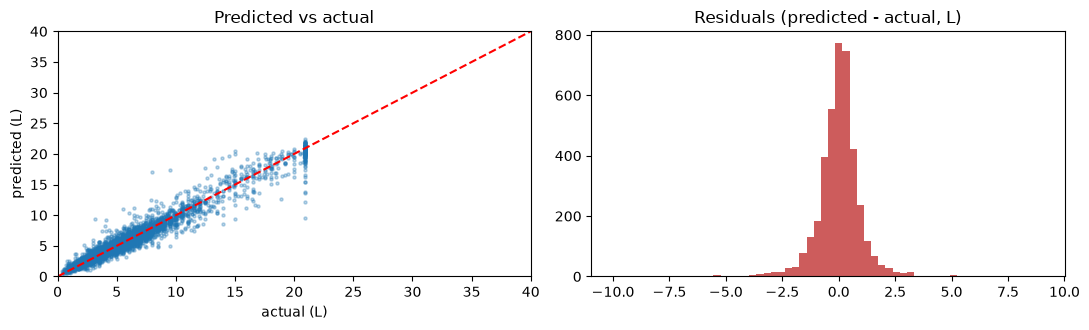

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].scatter(y_te, pred, s=5, alpha=.3)
ax[0].plot([0, 40], [0, 40], "r--")
ax[0].set(xlim=(0, 40), ylim=(0, 40), xlabel="actual (L)",
          ylabel="predicted (L)", title="Predicted vs actual")
ax[1].hist((pred - y_te).clip(-10, 10), bins=60, color="indianred")
ax[1].set(title="Residuals (predicted - actual, L)")
plt.tight_layout()
plt.show()

In [6]:
# Band agreement as a confusion matrix (bands are DERIVED from the price).
conf = pd.crosstab(pd.Series(true_band, name="actual"),
                   pd.Series(pred_band, name="predicted"))
conf

predicted,High,Low,Medium
actual,,,
High,1180,0,137
Low,2,1156,165
Medium,127,131,1066


### Error analysis & decision
Most residuals sit tightly around zero; the biggest misses are premium / rare
models with little data — a candidate for collecting more data or per-segment
models later. The KPI gate **passes**, so this model is cleared to ship (nb 07).

> **Key idea:** selection is *CV to choose, test set to confirm, KPI gate to
> decide*. Never tune against the test set — that would quietly turn it into
> another training set and inflate your confidence.